In [1]:
import pandas as pd

# Load the dataset (latin-1 encoding avoids a common error with this file)
df = pd.read_csv("spam.csv", encoding="latin-1")

# Keep only the first two columns and rename them
df = df.iloc[:, :2]
df.columns = ["label", "message"]

# Inspect the data
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset info:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (5572, 2)

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
label      0
message    0
dtype: int64

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Duplicate rows: 403


Rows before: 5572
Rows after removing duplicates: 5169

Unmapped labels (should be 0): 0

Label counts after cleaning:
label
ham     4516
spam     653
Name: count, dtype: int64

Average message length by label:
label
ham      70.5
spam    137.9
Name: length, dtype: float64

Sample rows:
     label                                            message  label_num  \
1566   ham                      Did u download the fring app?          0   
1988   ham  Pass dis to all ur contacts n see wat u get! R...          0   
1235   ham                                              Ok...          0   
2868   ham                     Am in film ill call you later.          0   
3435   ham  Sorry, left phone upstairs. OK, might be hecti...          0   

      length  
1566      29  
1988     276  
1235       5  
2868      30  
3435     107  


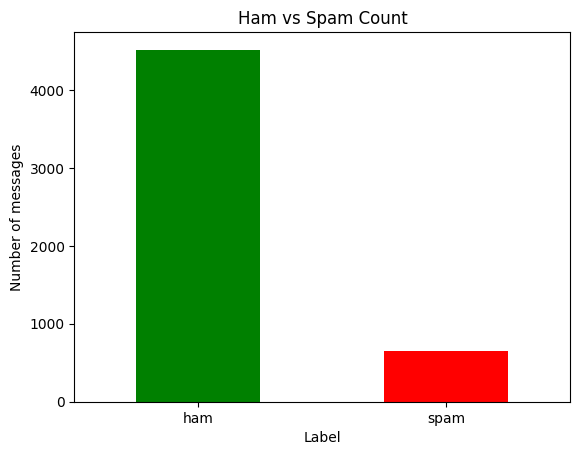

In [2]:
import matplotlib.pyplot as plt

# 1. Remove duplicate rows
print("Rows before:", len(df))
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

# 2. Convert labels to numbers: ham = 0, spam = 1
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
print("\nUnmapped labels (should be 0):", df["label_num"].isnull().sum())

# 3. Add a message length column
df["length"] = df["message"].str.len()

# 4. Look at the cleaned data
print("\nLabel counts after cleaning:")
print(df["label"].value_counts())

print("\nAverage message length by label:")
print(df.groupby("label")["length"].mean().round(1))

print("\nSample rows:")
print(df.sample(5, random_state=42))

# 5. Bar chart of ham vs spam
df["label"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Ham vs Spam Count")
plt.xlabel("Label")
plt.ylabel("Number of messages")
plt.xticks(rotation=0)
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Inputs (X) and answers (y)
X = df["message"]
y = df["label_num"]

# 2. Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nSpam share in training:", round(y_train.mean() * 100, 2), "%")
print("Spam share in testing:", round(y_test.mean() * 100, 2), "%")

# 3. Convert text to numbers with TF-IDF
vectorizer = TfidfVectorizer(stop_words="english", lowercase=True)
X_train_tfidf = vectorizer.fit_transform(X_train)  # learn words from training data only
X_test_tfidf = vectorizer.transform(X_test)        # reuse the same words for testing

print("\nTF-IDF shape (train):", X_train_tfidf.shape)
print("TF-IDF shape (test):", X_test_tfidf.shape)
print("Number of unique words learned:", len(vectorizer.get_feature_names_out()))
print("Example words:", list(vectorizer.get_feature_names_out()[:10]))

Training messages: 4135
Testing messages: 1034

Spam share in training: 12.62 %
Spam share in testing: 12.67 %

TF-IDF shape (train): (4135, 7329)
TF-IDF shape (test): (1034, 7329)
Number of unique words learned: 7329
Example words: ['00', '000', '000pes', '008704050406', '0089', '0121', '01223585236', '01223585334', '0125698789', '02']


Model trained successfully!

Accuracy: 96.62 %

Classification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034

Confusion matrix:
[[902   1]
 [ 34  97]]


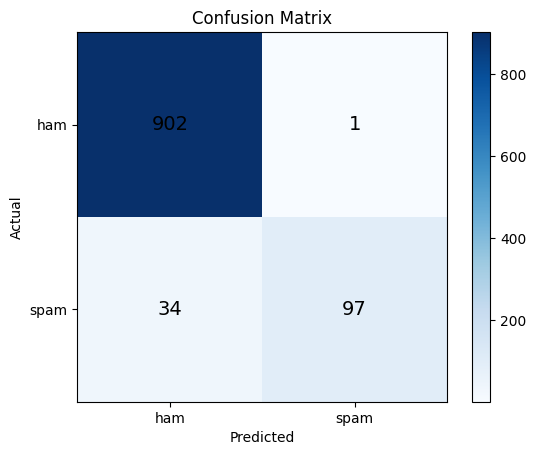

In [4]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# 1. Create and train the model
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)
print("Model trained successfully!")

# 2. Predict on the test messages
y_pred = model.predict(X_test_tfidf)

# 3. Accuracy
print("\nAccuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# 4. Precision, recall, F1-score
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

# 5. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:")
print(cm)

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["ham", "spam"])
plt.yticks([0, 1], ["ham", "spam"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.colorbar()
plt.show()

In [5]:
import joblib
from google.colab import files

# 1. Function to check any message
def check_message(text):
    text_tfidf = vectorizer.transform([text])
    prediction = model.predict(text_tfidf)[0]
    spam_probability = model.predict_proba(text_tfidf)[0][1]
    label = "SPAM" if prediction == 1 else "HAM (not spam)"
    print(f"Message: {text}")
    print(f"Result: {label} (spam probability: {spam_probability * 100:.1f}%)\n")

# 2. Try some messages
check_message("Congratulations! You have won a free iPhone. Click here to claim your prize now!")
check_message("URGENT! Your account is blocked. Send your bank details to claim 1000 cash")
check_message("Hi, are we meeting at the college library at 4 pm today?")
check_message("Please send me the project report before tomorrow morning.")

# 3. Save the model and vectorizer
joblib.dump(model, "spam_model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")
print("Saved: spam_model.pkl and vectorizer.pkl")

# 4. Download both files to your computer
files.download("spam_model.pkl")
files.download("vectorizer.pkl")

Message: Congratulations! You have won a free iPhone. Click here to claim your prize now!
Result: SPAM (spam probability: 87.1%)

Message: URGENT! Your account is blocked. Send your bank details to claim 1000 cash
Result: SPAM (spam probability: 72.7%)

Message: Hi, are we meeting at the college library at 4 pm today?
Result: HAM (not spam) (spam probability: 0.7%)

Message: Please send me the project report before tomorrow morning.
Result: HAM (not spam) (spam probability: 1.3%)

Saved: spam_model.pkl and vectorizer.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>